In [48]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [49]:
dataset = pd.read_csv('./data/Salary_Data.csv')
x = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

print(x)
print(y)

[[ 1.1]
 [ 1.3]
 [ 1.5]
 [ 2. ]
 [ 2.2]
 [ 2.9]
 [ 3. ]
 [ 3.2]
 [ 3.2]
 [ 3.7]
 [ 3.9]
 [ 4. ]
 [ 4. ]
 [ 4.1]
 [ 4.5]
 [ 4.9]
 [ 5.1]
 [ 5.3]
 [ 5.9]
 [ 6. ]
 [ 6.8]
 [ 7.1]
 [ 7.9]
 [ 8.2]
 [ 8.7]
 [ 9. ]
 [ 9.5]
 [ 9.6]
 [10.3]
 [10.5]]
[ 39343.  46205.  37731.  43525.  39891.  56642.  60150.  54445.  64445.
  57189.  63218.  55794.  56957.  57081.  61111.  67938.  66029.  83088.
  81363.  93940.  91738.  98273. 101302. 113812. 109431. 105582. 116969.
 112635. 122391. 121872.]


In [50]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=1/3, random_state=0)

### 모델 공부 시키기 (학습 단계)
scikit-learn에서 선형 회귀 알고리즘을 사용하기 위한 LinearRegression 도구를 볼러오고, `regressor = LinearRegression()`은 선형 회귀 계산을 수행할 인공지능 모델(객체)을 생성함. (아직 초기 단계 아무것도 모르는 상태의 모델)

`regressor.fit(x_train, y_train)`은 모델에게 모의고사 문제집(x_train)과 모의고사 해답지(y_train)를 주고 공부하라는 (fit)라고 지시하는 단계.

모델은 문제와 정답을 대조하면서 "경력이 1년 늘어날 때마다 연봉은 대략 얼마씩 오르는가?"와 같은 최적의 규칙(기울기와 절편, 즉 $y = ax + b$ 직선)을 수학적으로 찾아냄.

In [51]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9345.94]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.682e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[11.32]


### 실전 문제 풀어보기 (예측 단계)
예시를 든다면, 방금 공부를 마친 모델에게 실전 시험 문제지(x_test)만 건네주며, "너가 찾은 규칙으로 답을 적어봐(예측, Predict)"라고 지시함.

모델은 학습해 둔 직선 공식에 x_test의 숫자들을 대입해 계산된 결과값을 도출함.

In [52]:
y_pred = regressor.predict(x_test)

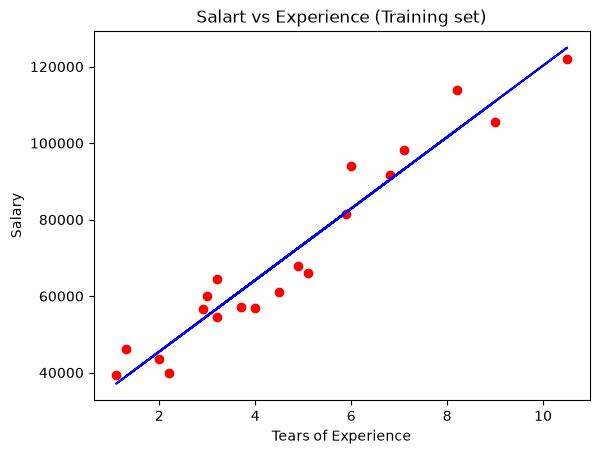

In [53]:
plt.scatter(x_train, y_train, color = 'red')
plt.plot(x_train, regressor.predict(x_train), color ='blue')
plt.title('Salart vs Experience (Training set)')
plt.xlabel('Tears of Experience')
plt.ylabel('Salary')
plt.show()

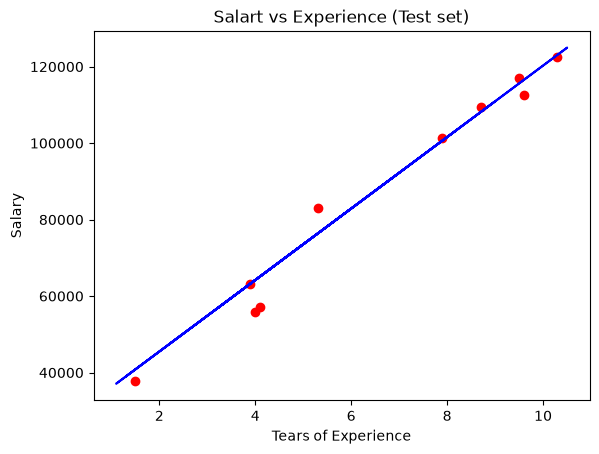

In [54]:
plt.scatter(x_test, y_test, color = 'red')
plt.plot(x_train, regressor.predict(x_train), color ='blue')
plt.title('Salart vs Experience (Test set)')
plt.xlabel('Tears of Experience')
plt.ylabel('Salary')
plt.show()